In [2]:
# STEP 1: LOAD DATASET AND PERFORM INITIAL ANALYSIS

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

OUTPUT_DIR = Path("outputs_car_unsupervised_clustering")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

possible_paths = [
    Path("car.xlsx"),
    Path("/mnt/data/car.xlsx")
]
DATA_PATH = next((p for p in possible_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError("Place car.xlsx in the notebook directory or update DATA_PATH.")

df = pd.read_excel(DATA_PATH, sheet_name="Raw_data")

print("DATASET OVERVIEW")
print("File:", DATA_PATH)
print("Shape:", df.shape)
print("\nFirst five records:")
display(df.head())
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nStatistical summary:")
display(df.describe(include="all").T)


DATASET OVERVIEW
File: car.xlsx
Shape: (3577, 10)

First five records:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,car age,price category
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner,19,Budget
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner,19,Budget
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner,14,Mid Range
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner,9,Budget
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner,12,Budget



Data types:
name              object
year               int64
selling_price      int64
km_driven          int64
fuel              object
seller_type       object
transmission      object
owner             object
car age            int64
price category    object
dtype: object

Missing values:
name              0
year              0
selling_price     0
km_driven         0
fuel              0
seller_type       0
transmission      0
owner             0
car age           0
price category    0
dtype: int64

Duplicate rows: 0

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
name,3577,1491,Maruti Swift Dzire VDI,54,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,3577.0,NaN,NaN,NaN,2012.962538,4.251759,1992.0,2010.0,2013.0,2016.0,2020.0
selling_price,3577.0,NaN,NaN,NaN,473912.542074,509301.809816,20000.0,200000.0,350000.0,600000.0,8900000.0
km_driven,3577.0,NaN,NaN,NaN,69250.545709,47579.940016,1.0,36000.0,60000.0,90000.0,806599.0
fuel,3577,5,Diesel,1800,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_type,3577,3,Individual,2832,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission,3577,2,Manual,3265,NaN,NaN,NaN,NaN,NaN,NaN,NaN
owner,3577,5,First Owner,2218,NaN,NaN,NaN,NaN,NaN,NaN,NaN
car age,3577.0,NaN,NaN,NaN,13.037462,4.251759,6.0,10.0,13.0,16.0,34.0
price category,3577,3,Budget,2356,NaN,NaN,NaN,NaN,NaN,NaN,NaN


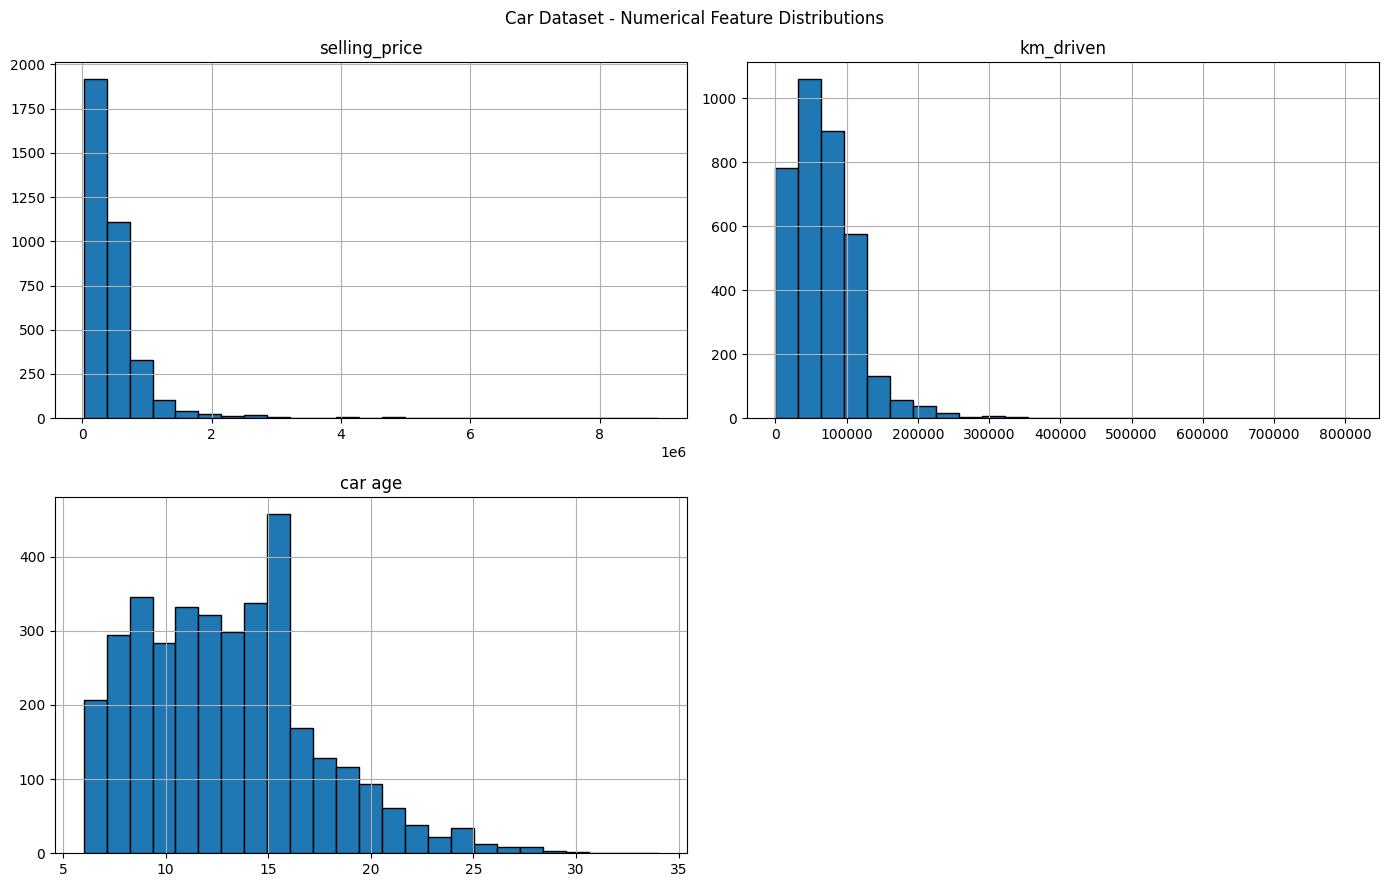

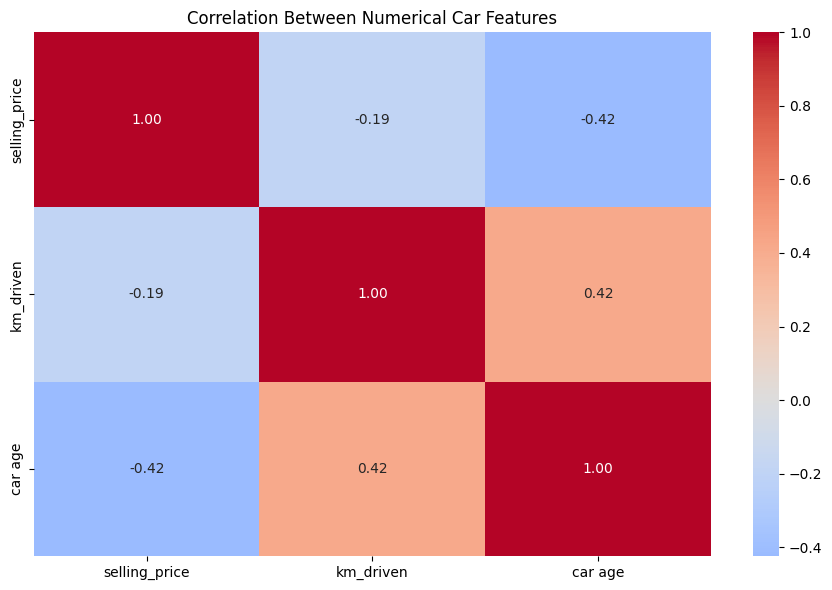

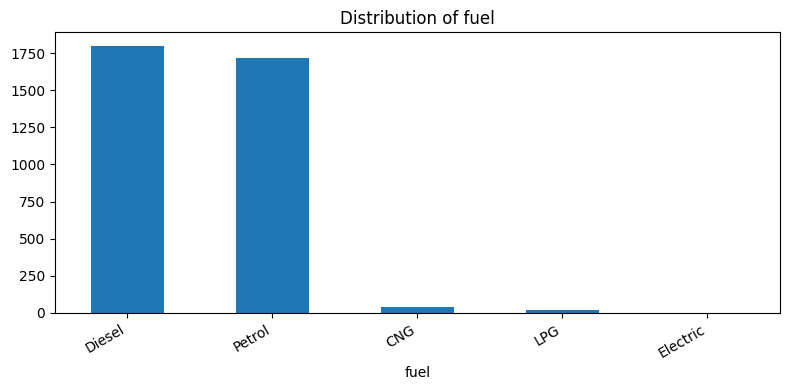

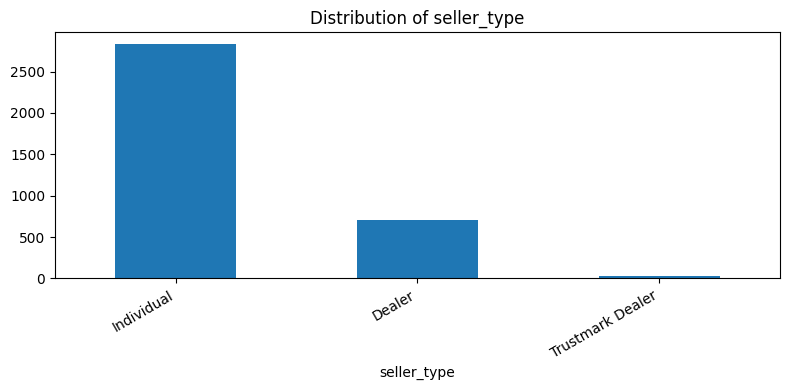

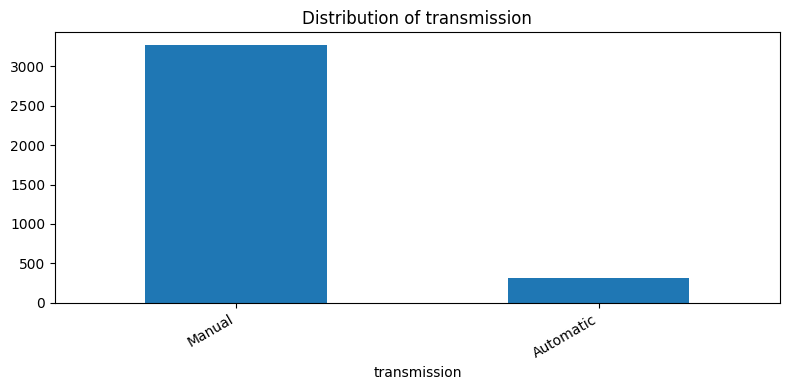

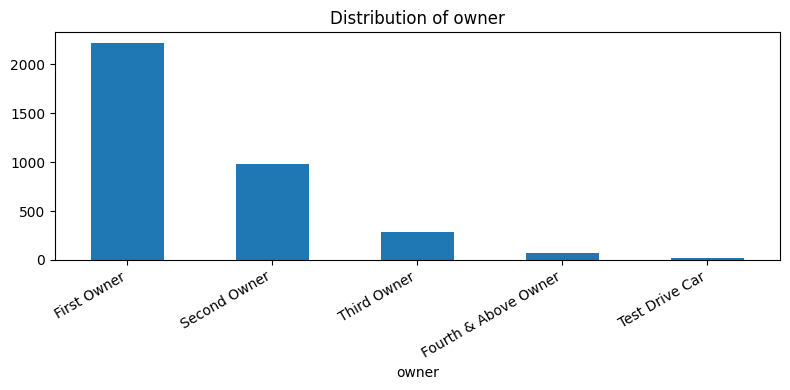

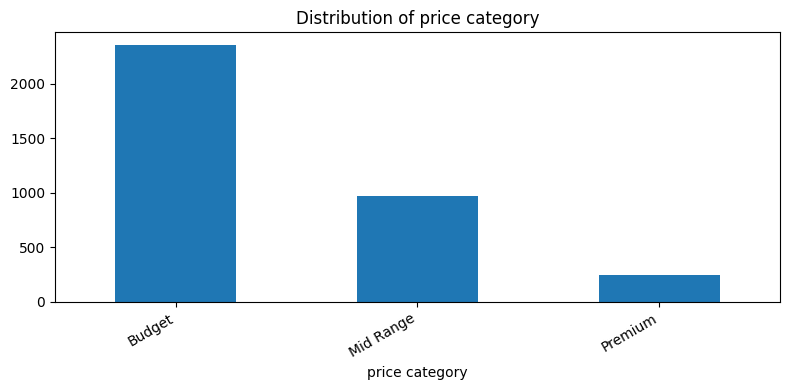

In [3]:
# STEP 2: EXPLORATORY DATA ANALYSIS

# "year" and "car age" contain the same information in this dataset.
# Therefore, car age is retained for clustering and year is not repeated in this correlation plot.
numeric_features_eda = [
    "selling_price", "km_driven", "car age"
]
available_numeric = [c for c in numeric_features_eda if c in df.columns]

df[available_numeric].hist(figsize=(14, 9), bins=25, edgecolor="black")
plt.suptitle("Car Dataset - Numerical Feature Distributions")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "feature_distributions.png", dpi=200, bbox_inches="tight")
plt.show()

plt.figure(figsize=(9, 6))
sns.heatmap(
    df[available_numeric].corr(),
    annot=True, fmt=".2f", cmap="coolwarm", center=0
)
plt.title("Correlation Between Numerical Car Features")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "correlation_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

for col in ["fuel", "seller_type", "transmission", "owner", "price category"]:
    if col in df.columns:
        plt.figure(figsize=(8, 4))
        order = df[col].value_counts().index
        df[col].value_counts().reindex(order).plot(kind="bar")
        plt.title(f"Distribution of {col}")
        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()
        plt.savefig(
            OUTPUT_DIR / f"{col.replace(' ', '_')}_distribution.png",
            dpi=200, bbox_inches="tight"
        )
        plt.show()


In [4]:
# STEP 3: SELECT FEATURES AND PREPROCESS DATA

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# "year" and "car age" are perfectly redundant in this dataset.
# Keep "car age" and remove "year" to avoid giving the same information twice.
# Price columns are reserved for post-clustering interpretation only.
# Car name is excluded because it is a high-cardinality identifier.
CLUSTER_FEATURES = [
    "km_driven", "fuel", "seller_type",
    "transmission", "owner", "car age"
]
POST_CLUSTER_COLUMNS = ["name", "year", "selling_price", "price category"]

missing_columns = [c for c in CLUSTER_FEATURES if c not in df.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# Verify the redundancy before removing year from the clustering inputs.
if {"year", "car age"}.issubset(df.columns):
    year_age_sum = df["year"] + df["car age"]
    print("Unique values of year + car age:", sorted(year_age_sum.dropna().unique())[:10])
    print("Year is excluded because it duplicates car age in this dataset.")

cluster_results = df.reset_index(drop=True).copy()
X_raw = cluster_results[CLUSTER_FEATURES].copy()

numeric_features = X_raw.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_raw.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", encoder)
])

transformers = []
if numeric_features:
    transformers.append(("numeric", numeric_pipeline, numeric_features))
if categorical_features:
    transformers.append(("categorical", categorical_pipeline, categorical_features))

preprocessor = ColumnTransformer(transformers=transformers, remainder="drop")
X_cluster = np.asarray(preprocessor.fit_transform(X_raw))

print("\nPreprocessing completed!")
print("Original features:", X_raw.shape[1])
print("Processed feature matrix:", X_cluster.shape)
print("Records available:", X_cluster.shape[0])
print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)
print("Excluded from clustering:", POST_CLUSTER_COLUMNS)


Unique values of year + car age: [np.int64(2026)]
Year is excluded because it duplicates car age in this dataset.

Preprocessing completed!
Original features: 6
Processed feature matrix: (3577, 17)
Records available: 3577
Numerical features: ['km_driven', 'car age']
Categorical features: ['fuel', 'seller_type', 'transmission', 'owner']
Excluded from clustering: ['name', 'year', 'selling_price', 'price category']


,K,Inertia,Silhouette Score
0,2,8984.0139,0.2721
1,3,7556.3869,0.2669
2,4,6605.5420,0.2433
3,5,5959.2224,0.2397
4,6,5443.8995,0.2471
5,7,5062.3236,0.2421
6,8,4731.7411,0.2499
7,9,4419.8074,0.2740
8,10,4183.2928,0.2820


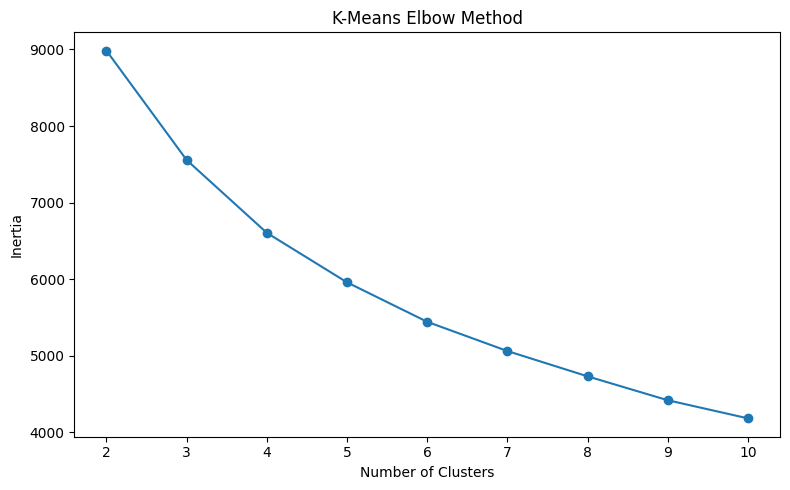

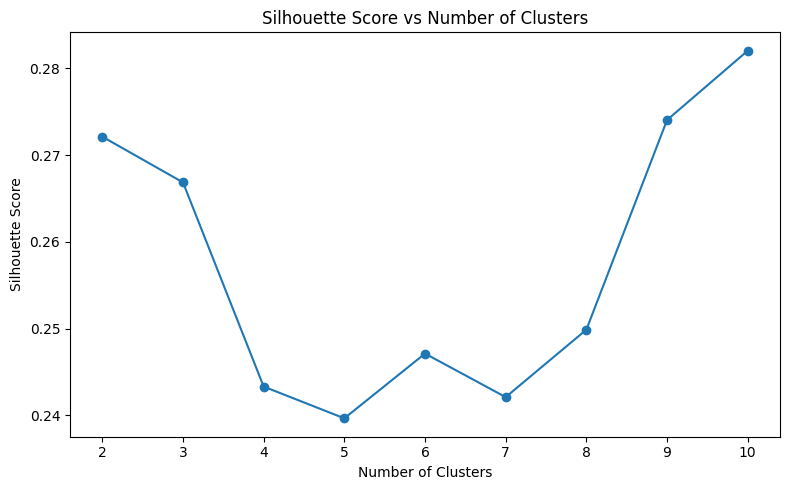

Best candidate K: 10


In [5]:
# STEP 4: K-MEANS ELBOW METHOD AND SILHOUETTE SCORE

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

n_samples = len(X_cluster)
if n_samples < 3:
    raise ValueError("At least three records are needed.")

k_values = range(2, min(11, n_samples))
k_results = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_cluster)
    score = silhouette_score(
        X_cluster, labels,
        sample_size=min(2000, n_samples), random_state=42
    )
    k_results.append({"K": k, "Inertia": model.inertia_, "Silhouette Score": score})

k_results_df = pd.DataFrame(k_results)
display(k_results_df.round(4))

plt.figure(figsize=(8, 5))
plt.plot(k_results_df["K"], k_results_df["Inertia"], marker="o")
plt.title("K-Means Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "elbow_method.png", dpi=200, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(k_results_df["K"], k_results_df["Silhouette Score"], marker="o")
plt.title("Silhouette Score vs Number of Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "silhouette_by_k.png", dpi=200, bbox_inches="tight")
plt.show()

best_k = int(k_results_df.loc[k_results_df["Silhouette Score"].idxmax(), "K"])
print("Best candidate K:", best_k)


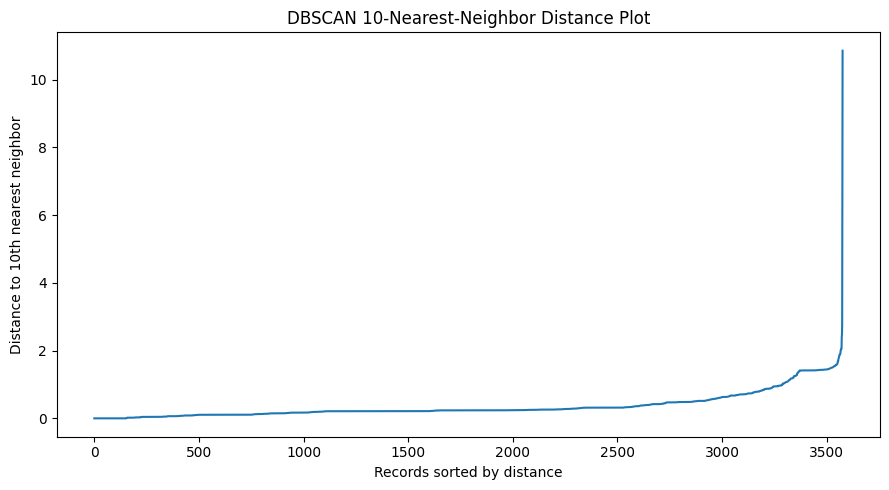

Training K-Means...
Training Hierarchical Clustering...

Initial comparison:


,Algorithm,Clusters Found,Noise Percentage,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,K-Means,10,0.0,0.2820,1.3069,804.2531
1,Hierarchical Clustering,10,0.0,0.2272,1.4969,581.7779


In [6]:
# STEP 5: TRAIN AND COMPARE THREE CLUSTERING ALGORITHMS

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.neighbors import NearestNeighbors

# Nearest-neighbor distance plot helps inspect a suitable DBSCAN eps.
neighbors = NearestNeighbors(n_neighbors=10)
neighbors.fit(X_cluster)
distances, _ = neighbors.kneighbors(X_cluster)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 5))
plt.plot(k_distances)
plt.title("DBSCAN 10-Nearest-Neighbor Distance Plot")
plt.xlabel("Records sorted by distance")
plt.ylabel("Distance to 10th nearest neighbor")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "dbscan_neighbor_distances.png", dpi=200, bbox_inches="tight")
plt.show()

def evaluate_clusters(X, labels, remove_noise=False):
    labels = np.asarray(labels)
    if remove_noise:
        mask = labels != -1
        X_eval, y_eval = X[mask], labels[mask]
    else:
        X_eval, y_eval = X, labels

    n_clusters = len(np.unique(y_eval))
    metrics = {
        "Silhouette Score": np.nan,
        "Davies-Bouldin Index": np.nan,
        "Calinski-Harabasz Score": np.nan
    }
    if 2 <= n_clusters < len(y_eval):
        metrics["Silhouette Score"] = silhouette_score(
            X_eval, y_eval, sample_size=min(2000, len(y_eval)), random_state=42
        )
        metrics["Davies-Bouldin Index"] = davies_bouldin_score(X_eval, y_eval)
        metrics["Calinski-Harabasz Score"] = calinski_harabasz_score(X_eval, y_eval)
    return metrics, n_clusters

models = {
    "K-Means": KMeans(n_clusters=best_k, random_state=42, n_init=10),
    "Hierarchical Clustering": AgglomerativeClustering(n_clusters=best_k, linkage="ward")
}

trained_models, labels_by_model, evaluation_results = {}, {}, []

for name, model in models.items():
    print(f"Training {name}...")
    labels = model.fit_predict(X_cluster)
    trained_models[name] = model
    labels_by_model[name] = labels
    metrics, n_clusters = evaluate_clusters(X_cluster, labels)
    evaluation_results.append({
        "Algorithm": name, "Clusters Found": n_clusters,
        "Noise Percentage": 0.0, **metrics
    })

results_df = pd.DataFrame(evaluation_results)
print("\nInitial comparison:")
display(results_df.round(4))


In [7]:
# STEP 6: DBSCAN HYPERPARAMETER TUNING

dbscan_rows = []
eps_values = [0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0, 2.5, 3.0]
min_samples_values = [5, 10, 15]

for eps in eps_values:
    for min_samples in min_samples_values:
        model = DBSCAN(eps=eps, min_samples=min_samples, n_jobs=-1)
        labels = model.fit_predict(X_cluster)
        noise_percentage = np.mean(labels == -1) * 100
        metrics, n_clusters = evaluate_clusters(
            X_cluster, labels, remove_noise=True
        )
        dbscan_rows.append({
            "eps": eps,
            "min_samples": min_samples,
            "Clusters Found": n_clusters,
            "Noise Percentage": noise_percentage,
            **metrics
        })

dbscan_tuning_df = pd.DataFrame(dbscan_rows)
valid_dbscan = dbscan_tuning_df[
    (dbscan_tuning_df["Clusters Found"] >= 2)
    & dbscan_tuning_df["Silhouette Score"].notna()
].copy()

# Prefer a valid solution with no more than 50% noise.
# If none exists, select the valid solution with the least noise.
acceptable_dbscan = valid_dbscan[
    valid_dbscan["Noise Percentage"] <= 50
]

if not acceptable_dbscan.empty:
    selected_dbscan = acceptable_dbscan.sort_values(
        "Silhouette Score", ascending=False
    ).iloc[0]
elif not valid_dbscan.empty:
    selected_dbscan = valid_dbscan.sort_values(
        ["Noise Percentage", "Silhouette Score"],
        ascending=[True, False]
    ).iloc[0]
else:
    selected_dbscan = None

if selected_dbscan is not None:
    DBSCAN_EPS = float(selected_dbscan["eps"])
    DBSCAN_MIN_SAMPLES = int(selected_dbscan["min_samples"])
    dbscan_model = DBSCAN(
        eps=DBSCAN_EPS,
        min_samples=DBSCAN_MIN_SAMPLES,
        n_jobs=-1
    )
    dbscan_labels = dbscan_model.fit_predict(X_cluster)
    trained_models["DBSCAN"] = dbscan_model
    labels_by_model["DBSCAN"] = dbscan_labels

    metrics, n_clusters = evaluate_clusters(
        X_cluster, dbscan_labels, remove_noise=True
    )
    noise_percentage = float(np.mean(dbscan_labels == -1) * 100)
    evaluation_results.append({
        "Algorithm": "DBSCAN",
        "Clusters Found": n_clusters,
        "Noise Percentage": noise_percentage,
        **metrics
    })

    print("Selected DBSCAN eps:", DBSCAN_EPS)
    print("Selected DBSCAN min_samples:", DBSCAN_MIN_SAMPLES)
    print("DBSCAN clusters found:", n_clusters)
    print(f"DBSCAN noise records: {np.sum(dbscan_labels == -1)}")
    print(f"DBSCAN noise percentage: {noise_percentage:.2f}%")
    print(
        "Interpretation: DBSCAN noise records (label -1) are cars "
        "that do not belong to a sufficiently dense neighborhood."
    )
else:
    DBSCAN_EPS, DBSCAN_MIN_SAMPLES = None, None
    print(
        "DBSCAN did not find a valid multi-cluster solution "
        "for the tested parameters."
    )
    print(
        "Its noise percentage and parameter search results are still "
        "reported; its clustering metrics may be unavailable."
    )

results_df = pd.DataFrame(evaluation_results).sort_values(
    "Silhouette Score", ascending=False, na_position="last"
).reset_index(drop=True)

print("\n========== CLUSTERING MODEL COMPARISON ==========")
display(results_df.round(4))
print("\n========== DBSCAN PARAMETER SEARCH ==========")
display(
    dbscan_tuning_df.sort_values(
        "Silhouette Score", ascending=False, na_position="last"
    ).round(4)
)


Selected DBSCAN eps: 0.5
Selected DBSCAN min_samples: 15
DBSCAN clusters found: 13
DBSCAN noise records: 612
DBSCAN noise percentage: 17.11%
Interpretation: DBSCAN noise records (label -1) are cars that do not belong to a sufficiently dense neighborhood.

========== CLUSTERING MODEL COMPARISON ==========


,Algorithm,Clusters Found,Noise Percentage,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,DBSCAN,13,17.1093,0.3050,1.0009,447.5427
1,K-Means,10,0.0000,0.2820,1.3069,804.2531
2,Hierarchical Clustering,10,0.0000,0.2272,1.4969,581.7779



========== DBSCAN PARAMETER SEARCH ==========


,eps,min_samples,Clusters Found,Noise Percentage,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
2,0.50,15,13,17.1093,0.3050,1.0009,447.5427
1,0.50,10,14,14.6212,0.2882,1.0404,416.6690
5,0.75,15,16,10.3998,0.2699,1.0870,348.0094
11,1.25,15,18,5.5633,0.2626,1.2228,299.0883
8,1.00,15,18,6.7375,0.2596,1.1733,309.2101
10,1.25,10,21,4.2494,0.2589,1.2264,255.2554
7,1.00,10,19,5.6472,0.2461,1.1879,287.3230
4,0.75,10,20,7.1289,0.2444,1.1026,286.9813
3,0.75,5,29,3.9419,0.2443,1.0541,199.8377
0,0.50,5,28,7.7439,0.2413,0.9401,219.4076


========== K-MEANS CAR CLUSTER PROFILES ==========


,Record Count,car age,km_driven,selling_price
Cluster,,,,
0,499,14.19,97872.95,402919.79
1,538,8.98,28123.19,467092.89
2,304,14.63,67783.25,252373.93
3,346,11.36,56478.00,838595.34
4,477,9.52,42036.43,873379.42
5,279,10.70,36433.81,538261.59
6,125,16.03,217970.56,364039.94
7,348,15.74,64727.04,207999.97
8,313,21.73,85342.44,116580.21


========== COMMON CAR CHARACTERISTICS BY CLUSTER ==========


,fuel,seller_type,transmission,owner,price category
Cluster,,,,,
0,Diesel,Individual,Manual,Second Owner,Budget
1,Petrol,Individual,Manual,First Owner,Budget
2,Petrol,Individual,Manual,Second Owner,Budget
3,Diesel,Dealer,Manual,First Owner,Mid Range
4,Diesel,Individual,Manual,First Owner,Mid Range
5,Petrol,Dealer,Manual,First Owner,Budget
6,Diesel,Individual,Manual,First Owner,Budget
7,Petrol,Individual,Manual,First Owner,Budget
8,Petrol,Individual,Manual,Second Owner,Budget


========== CLUSTER INTERPRETATION ==========
Cluster 0: 499 cars; average car age = 14.2 years; average kilometres driven = 97,873; average selling price = 402,920; common fuel = Diesel; common transmission = Manual; common owner category = Second Owner; most common price category = Budget.
Cluster 1: 538 cars; average car age = 9.0 years; average kilometres driven = 28,123; average selling price = 467,093; common fuel = Petrol; common transmission = Manual; common owner category = First Owner; most common price category = Budget.
Cluster 2: 304 cars; average car age = 14.6 years; average kilometres driven = 67,783; average selling price = 252,374; common fuel = Petrol; common transmission = Manual; common owner category = Second Owner; most common price category = Budget.
Cluster 3: 346 cars; average car age = 11.4 years; average kilometres driven = 56,478; average selling price = 838,595; common fuel = Diesel; common transmission = Manual; common owner category = First Owner; most co

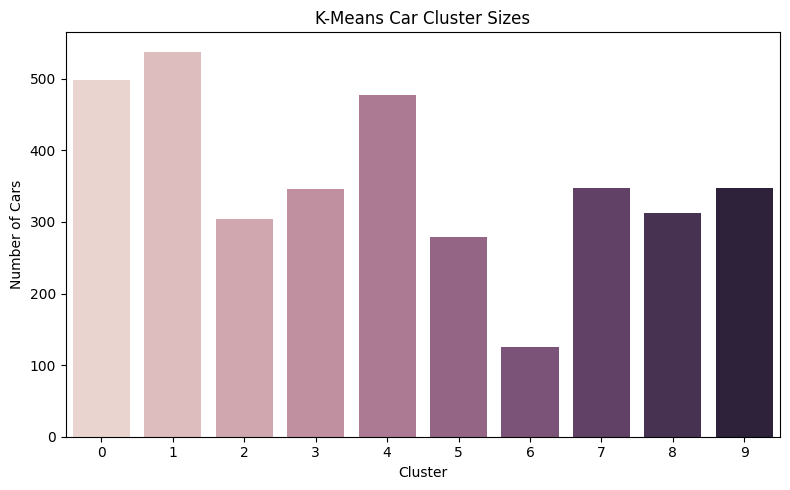

Price category distribution within each K-Means cluster:


price category,Budget,Mid Range,Premium
Cluster,,,
0,0.766,0.198,0.036
1,0.595,0.383,0.022
2,0.951,0.036,0.013
3,0.332,0.477,0.191
4,0.216,0.568,0.216
5,0.624,0.305,0.072
6,0.744,0.216,0.040
7,0.968,0.026,0.006
8,0.990,0.010,0.000



========== DBSCAN NOISE SUMMARY ==========
Noise records: 612
Noise percentage: 17.11%
Noise records are not assigned to a regular DBSCAN cluster because they do not meet the selected density requirement.


In [8]:
# STEP 7: CLUSTER PROFILES AND INTERPRETATION

for name, labels in labels_by_model.items():
    safe_name = name.replace(" ", "_").replace("-", "_")
    cluster_results[f"{safe_name}_Cluster"] = labels

cluster_results["Cluster"] = labels_by_model["K-Means"]

# Numerical profile: describe car age, usage and selling price after clustering.
# selling_price is used only for interpretation, not as a clustering input.
profile_features = ["car age", "km_driven", "selling_price"]
cluster_profile = (
    cluster_results.groupby("Cluster")[profile_features]
    .mean()
    .round(2)
)
cluster_profile.insert(
    0, "Record Count",
    cluster_results.groupby("Cluster").size()
)

print("========== K-MEANS CAR CLUSTER PROFILES ==========")
display(cluster_profile)

def most_common_value(series):
    modes = series.mode(dropna=True)
    return modes.iloc[0] if len(modes) else "Unknown"

categorical_profile = cluster_results.groupby("Cluster").agg({
    "fuel": most_common_value,
    "seller_type": most_common_value,
    "transmission": most_common_value,
    "owner": most_common_value,
    "price category": most_common_value
})

print("========== COMMON CAR CHARACTERISTICS BY CLUSTER ==========")
display(categorical_profile)

# Create concise, data-driven descriptions for every K-Means cluster.
print("========== CLUSTER INTERPRETATION ==========")
cluster_interpretations = []

for cluster_id in cluster_profile.index:
    numeric_row = cluster_profile.loc[cluster_id]
    category_row = categorical_profile.loc[cluster_id]

    description = (
        f"Cluster {cluster_id}: {int(numeric_row['Record Count'])} cars; "
        f"average car age = {numeric_row['car age']:.1f} years; "
        f"average kilometres driven = {numeric_row['km_driven']:,.0f}; "
        f"average selling price = {numeric_row['selling_price']:,.0f}; "
        f"common fuel = {category_row['fuel']}; "
        f"common transmission = {category_row['transmission']}; "
        f"common owner category = {category_row['owner']}; "
        f"most common price category = {category_row['price category']}."
    )
    cluster_interpretations.append(description)
    print(description)

plt.figure(figsize=(8, 5))
sns.countplot(data=cluster_results, x="Cluster", hue="Cluster", legend=False)
plt.title("K-Means Car Cluster Sizes")
plt.xlabel("Cluster")
plt.ylabel("Number of Cars")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "cluster_sizes.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

# Post-hoc comparison only: price category was not used to create clusters.
price_comparison = pd.crosstab(
    cluster_results["Cluster"],
    cluster_results["price category"],
    normalize="index"
).round(3)

print("Price category distribution within each K-Means cluster:")
display(price_comparison)
price_comparison.to_csv(OUTPUT_DIR / "cluster_vs_price_category.csv")

# DBSCAN noise summary: -1 means an observation was classified as noise.
if "DBSCAN" in labels_by_model:
    dbscan_noise_count = int(np.sum(labels_by_model["DBSCAN"] == -1))
    dbscan_noise_percentage = (
        dbscan_noise_count / len(labels_by_model["DBSCAN"]) * 100
    )
    print("\n========== DBSCAN NOISE SUMMARY ==========")
    print("Noise records:", dbscan_noise_count)
    print(f"Noise percentage: {dbscan_noise_percentage:.2f}%")
    print(
        "Noise records are not assigned to a regular DBSCAN cluster "
        "because they do not meet the selected density requirement."
    )


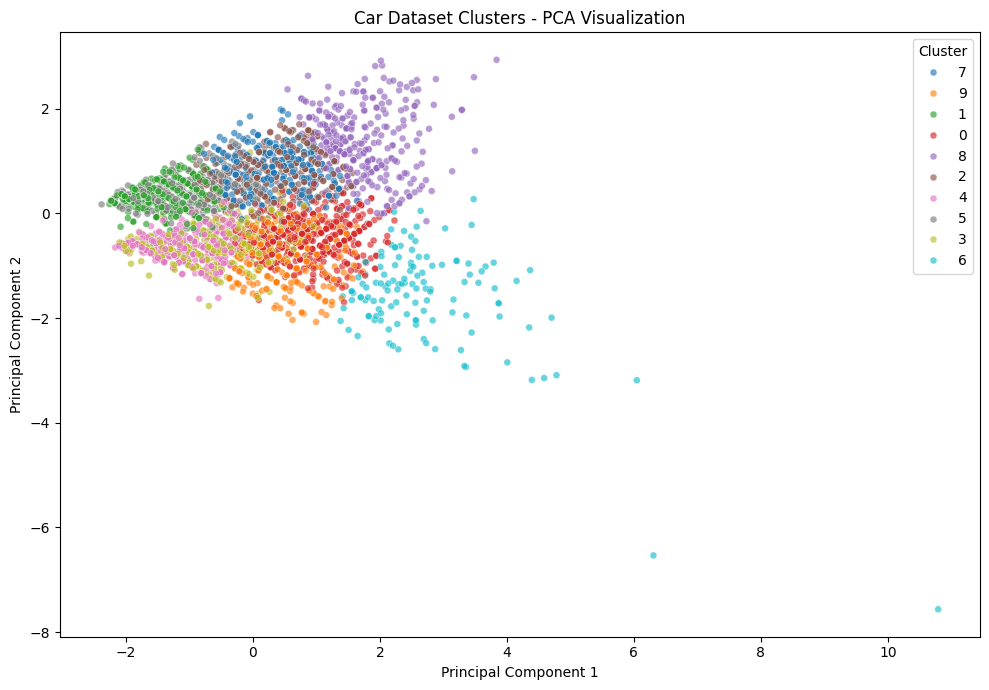

Variance explained by two PCA components: 64.41 %


In [9]:
# STEP 8: PCA VISUALIZATION

from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_cluster)

pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": labels_by_model["K-Means"].astype(str)
})

plt.figure(figsize=(10, 7))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Cluster",
                palette="tab10", alpha=0.65, s=25)
plt.title("Car Dataset Clusters - PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "pca_cluster_visualization.png", dpi=200, bbox_inches="tight")
plt.show()

print("Variance explained by two PCA components:",
      round(pca.explained_variance_ratio_.sum() * 100, 2), "%")


In [10]:
# STEP 9: FINAL ALGORITHM COMPARISON AND VERIFICATION

expected_algorithms = {
    "K-Means",
    "Hierarchical Clustering",
    "DBSCAN"
}
actual_algorithms = set(results_df["Algorithm"])

print("========== FINAL ALGORITHM COMPARISON ==========")
display(results_df.round(4))

if actual_algorithms == expected_algorithms:
    print("\nVerification passed: exactly the three required algorithms are included.")
else:
    print("\nAlgorithm verification warning.")
    print("Expected:", sorted(expected_algorithms))
    print("Found:", sorted(actual_algorithms))

valid_results = results_df.dropna(subset=["Silhouette Score"])
if not valid_results.empty:
    winner = valid_results.iloc[0]
    print("\nBest candidate by Silhouette Score:", winner["Algorithm"])
    print("Clusters:", int(winner["Clusters Found"]))
    print("Silhouette Score:", round(winner["Silhouette Score"], 4))
else:
    print("\nNo valid Silhouette Score was available for comparison.")

print("\n========== EVALUATION GUIDE ==========")
print("- Higher Silhouette Score generally indicates better-separated clusters.")
print("- Lower Davies-Bouldin Index generally indicates better clustering.")
print("- Higher Calinski-Harabasz Score generally indicates denser, better-separated clusters.")
print("- DBSCAN may mark records as noise (-1); always consider its noise percentage.")
print("- A higher score alone does not prove that a model is best.")
print("- Review cluster sizes and car characteristics before choosing a useful model.")

if "DBSCAN" in results_df["Algorithm"].values:
    dbscan_row = results_df[results_df["Algorithm"] == "DBSCAN"].iloc[0]
    print(
        f"\nDBSCAN assigned {dbscan_row['Noise Percentage']:.2f}% "
        "of records to noise."
    )


========== FINAL ALGORITHM COMPARISON ==========


,Algorithm,Clusters Found,Noise Percentage,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,DBSCAN,13,17.1093,0.3050,1.0009,447.5427
1,K-Means,10,0.0000,0.2820,1.3069,804.2531
2,Hierarchical Clustering,10,0.0000,0.2272,1.4969,581.7779



Verification passed: exactly the three required algorithms are included.

Best candidate by Silhouette Score: DBSCAN
Clusters: 13
Silhouette Score: 0.305

========== EVALUATION GUIDE ==========
- Higher Silhouette Score generally indicates better-separated clusters.
- Lower Davies-Bouldin Index generally indicates better clustering.
- Higher Calinski-Harabasz Score generally indicates denser, better-separated clusters.
- DBSCAN may mark records as noise (-1); always consider its noise percentage.
- A higher score alone does not prove that a model is best.
- Review cluster sizes and car characteristics before choosing a useful model.

DBSCAN assigned 17.11% of records to noise.


In [11]:
# STEP 10: SAVE CLUSTERING RESULTS, MODELS AND FINAL REPORT

import joblib
import json

cluster_results.to_csv(OUTPUT_DIR / "cluster_assignments.csv", index=False)
results_df.to_csv(OUTPUT_DIR / "clustering_model_comparison.csv", index=False)
k_results_df.to_csv(OUTPUT_DIR / "kmeans_k_selection.csv", index=False)
cluster_profile.to_csv(OUTPUT_DIR / "cluster_profiles.csv")
categorical_profile.to_csv(OUTPUT_DIR / "cluster_categories.csv")
dbscan_tuning_df.to_csv(OUTPUT_DIR / "dbscan_tuning_results.csv", index=False)
price_comparison.to_csv(OUTPUT_DIR / "cluster_vs_price_category.csv")

joblib.dump(preprocessor, OUTPUT_DIR / "preprocessor.joblib", compress=3)
for model_name, model in trained_models.items():
    safe_name = model_name.lower().replace(" ", "_").replace("-", "_")
    joblib.dump(model, OUTPUT_DIR / f"{safe_name}_model.joblib", compress=3)

metadata = {
    "input_features": CLUSTER_FEATURES,
    "excluded_from_clustering": POST_CLUSTER_COLUMNS,
    "algorithms": list(trained_models.keys()),
    "selected_k": int(best_k),
    "dbscan_eps": DBSCAN_EPS,
    "dbscan_min_samples": DBSCAN_MIN_SAMPLES,
    "note": "year was excluded because it duplicates car age in this dataset."
}
with open(OUTPUT_DIR / "model_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)

summary = [
    "UNSUPERVISED MACHINE LEARNING - CAR DATASET",
    "",
    "Algorithms: K-Means, Hierarchical Clustering, DBSCAN",
    "Clustering features: " + ", ".join(CLUSTER_FEATURES),
    "Excluded from clustering: " + ", ".join(POST_CLUSTER_COLUMNS),
    "",
    "FEATURE SELECTION NOTE",
    "The year and car age columns contain duplicate information in this dataset.",
    "Car age was retained and year was excluded from clustering.",
    "Selling price and price category were used only for post-clustering interpretation.",
    "",
    "FINAL ALGORITHM COMPARISON",
    results_df.round(4).to_string(index=False),
    "",
    "K-MEANS NUMERICAL CLUSTER PROFILES",
    cluster_profile.to_string(),
    "",
    "K-MEANS CATEGORICAL CLUSTER PROFILES",
    categorical_profile.to_string(),
    "",
    "DATA-DRIVEN CLUSTER INTERPRETATIONS",
    *cluster_interpretations,
    "",
    "DBSCAN INTERPRETATION",
    (
        f"Selected eps = {DBSCAN_EPS}, min_samples = {DBSCAN_MIN_SAMPLES}."
        if DBSCAN_EPS is not None
        else "No valid multi-cluster DBSCAN configuration was found in the tested grid."
    ),
    (
        f"DBSCAN noise percentage = "
        f"{np.mean(labels_by_model['DBSCAN'] == -1) * 100:.2f}%."
        if "DBSCAN" in labels_by_model
        else "DBSCAN labels were not available."
    ),
    "A DBSCAN label of -1 indicates a noise record that does not belong to a dense cluster.",
    "",
    "EVALUATION NOTES",
    "Higher Silhouette Score generally indicates better-separated clusters.",
    "Lower Davies-Bouldin Index generally indicates better clustering.",
    "Higher Calinski-Harabasz Score generally indicates denser, better-separated clusters.",
    "The best model should be selected using metrics, noise percentage, cluster sizes and interpretability together.",
    "",
    "ALGORITHM VERIFICATION",
    "Expected algorithms: K-Means, Hierarchical Clustering and DBSCAN.",
    "Actual algorithms: " + ", ".join(results_df["Algorithm"].tolist())
]
(OUTPUT_DIR / "final_project_report.txt").write_text(
    "\n".join(summary) + "\n",
    encoding="utf-8"
)

print("========== PROJECT COMPLETED ==========")
print("Algorithms verified:", list(results_df["Algorithm"]))
print("Output directory:", OUTPUT_DIR.resolve())
print("Generated files:")
for file_path in sorted(OUTPUT_DIR.iterdir()):
    if file_path.is_file():
        print(f"{file_path.name} - {file_path.stat().st_size / 1024:.1f} KB")


========== PROJECT COMPLETED ==========
Algorithms verified: ['DBSCAN', 'K-Means', 'Hierarchical Clustering']
Output directory: /content/outputs_car_unsupervised_clustering
Generated files:
cluster_assignments.csv - 347.7 KB
cluster_categories.csv - 0.5 KB
cluster_profiles.csv - 0.4 KB
cluster_sizes.png - 39.7 KB
cluster_vs_price_category.csv - 0.2 KB
clustering_model_comparison.csv - 0.3 KB
correlation_heatmap.png - 67.2 KB
dbscan_model.joblib - 31.4 KB
dbscan_neighbor_distances.png - 63.9 KB
dbscan_tuning_results.csv - 1.6 KB
elbow_method.png - 69.1 KB
feature_distributions.png - 102.0 KB
final_project_report.txt - 5.7 KB
fuel_distribution.png - 44.7 KB
hierarchical_clustering_model.joblib - 20.4 KB
k_means_model.joblib - 4.4 KB
kmeans_k_selection.csv - 0.4 KB
model_metadata.json - 0.5 KB
owner_distribution.png - 67.4 KB
pca_cluster_visualization.png - 460.4 KB
preprocessor.joblib - 1.7 KB
price_category_distribution.png - 48.0 KB
seller_type_distribution.png - 51.4 KB
silhouette_by_